<a href="https://colab.research.google.com/github/asmisnehav-spec/Customer-Segmentation-Project/blob/main/Predictive_Analytics_Using_Historical_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

In [3]:
# Load the dataset using the simple file name
df = pd.read_csv("US_Regional_Sales_Data.csv")

# Clean financial columns and calculate total sales
df["Unit Cost"] = (
    df["Unit Cost"].astype(str).str.replace(",", "").astype(float)
)
df["Unit Price"] = (
    df["Unit Price"].astype(str).str.replace(",", "").astype(float)
)
df["Total Sales"] = df["Order Quantity"] * df["Unit Price"]

# Display the first few rows
print(df.head())

   OrderNumber Sales Channel WarehouseCode ProcuredDate OrderDate ShipDate  \
0  SO - 000101      In-Store  WARE-UHY1004     31/12/17   31/5/18  14/6/18   
1  SO - 000102        Online  WARE-NMK1003     31/12/17   31/5/18  22/6/18   
2  SO - 000103   Distributor  WARE-UHY1004     31/12/17   31/5/18  21/6/18   
3  SO - 000104     Wholesale  WARE-NMK1003     31/12/17   31/5/18   2/6/18   
4  SO - 000105   Distributor  WARE-NMK1003      10/4/18   31/5/18  16/6/18   

  DeliveryDate CurrencyCode  _SalesTeamID  _CustomerID  _StoreID  _ProductID  \
0      19/6/18          USD             6           15       259          12   
1       2/7/18          USD            14           20       196          27   
2       1/7/18          USD            21           16       213          16   
3       7/6/18          USD            28           48       107          23   
4      26/6/18          USD            22           49       111          26   

   Order Quantity  Discount Applied  Unit Cost  Un

In [4]:
# Convert OrderDate to datetime and handle the date format
df["OrderDate"] = pd.to_datetime(df["OrderDate"], format="%d/%m/%y")

# Group by order date to get total daily sales, then sort chronologically
daily_sales = (
    df.groupby("OrderDate")["Total Sales"].sum().reset_index().sort_values("OrderDate")
)

# Convert dates into ordinal numerical values for regression
daily_sales["date_ordinal"] = daily_sales["OrderDate"].map(lambda x: x.toordinal())

print(daily_sales.head())

   OrderDate  Total Sales  date_ordinal
0 2018-05-31      75629.6        736845
1 2018-06-01     148961.1        736846
2 2018-06-02      79696.5        736847
3 2018-06-03     214125.3        736848
4 2018-06-04     100392.8        736849


In [5]:
# Define independent feature (X) and target variable (y)
X = daily_sales[["date_ordinal"]]
y = daily_sales["Total Sales"]

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training complete successfully!")

Model training complete successfully!


Mean Squared Error: 1420132164.7710354
Mean Absolute Error: 29680.55793043829


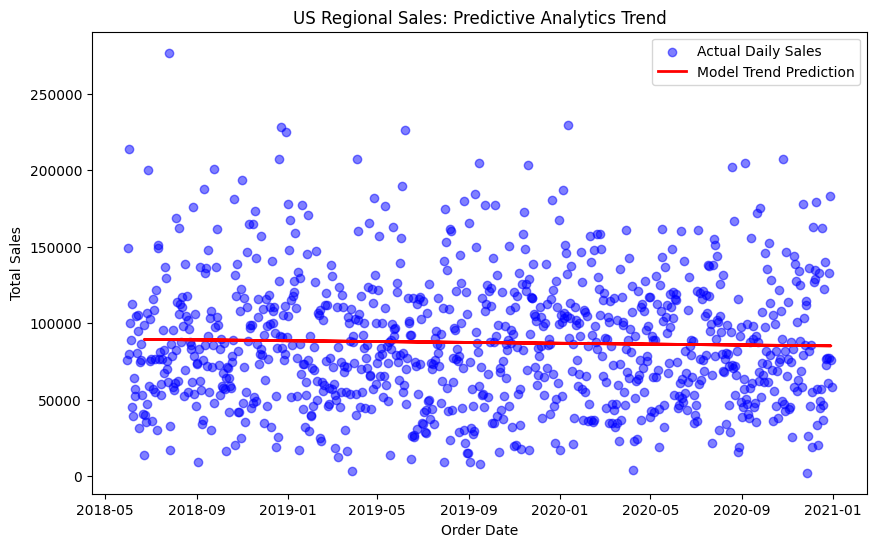

In [7]:
# Generate predictions on the test set
predictions = model.predict(X_test)

# Calculate and print evaluation metrics
print("Mean Squared Error:", mean_squared_error(y_test, predictions))
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))

# Convert ordinal values back to actual datetime objects properly using fromordinal
test_dates = [
    pd.Timestamp.fromordinal(int(o)) for o in X_test["date_ordinal"]
]

# Visualize actual sales vs model predictions properly
plt.figure(figsize=(10, 6))
plt.scatter(
    daily_sales["OrderDate"],
    daily_sales["Total Sales"],
    color="blue",
    alpha=0.5,
    label="Actual Daily Sales",
)
plt.plot(
    test_dates,
    predictions,
    color="red",
    linewidth=2,
    label="Model Trend Prediction",
)
plt.xlabel("Order Date")
plt.ylabel("Total Sales")
plt.title("US Regional Sales: Predictive Analytics Trend")
plt.legend()
plt.show()